In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [2]:
tags = ["charts/episodic_return", "eval/mu"]
# AIRL
results_airl_200k = pkl.load(open('../irm_pkl/240324_sac_airl_load.pkl','rb'))
results_airl_200k_pert02 = pkl.load(open('../irm_pkl/010424_sac_airl_load_pert02.pkl','rb'))
results_airl_200k_pert05 = pkl.load(open('../irm_pkl/040424_sac_airl_load_200k_pert05.pkl','rb'))
results_airl_200k_pert10 = pkl.load(open('../irm_pkl/040424_sac_airl_load_200k_pert10.pkl','rb'))
results_airl_anthum_200k_pert05 = pkl.load(open('../irm_pkl/080424_sac_airl_load_anthum_200k_pert05.pkl','rb'))
results_airl_anthum_200k_pert10 = pkl.load(open('../irm_pkl/080424_sac_airl_load_anthum_200k_pert10.pkl','rb'))

results_airl_800k = pkl.load(open('../irm_pkl/300324_sac_airl_load_800k.pkl','rb'))
# GAIL
results_gail_200k_01 = pkl.load(open('../irm_pkl/260324_sac_gail_load.pkl','rb'))
results_gail_800k = pkl.load(open('../irm_pkl/300324_sac_gail_load_800k.pkl','rb'))
results_gail_200k_03 = pkl.load(open('../irm_pkl/040424_sac_gail_load_200k_pert03.pkl','rb'))

results_meirl_800k = pkl.load(open('../irm_pkl/300324_sac_meirl_load_800k.pkl','rb'))
results_meirl_200k = pkl.load(open('../irm_pkl/030424_sac_meirl_load_200k.pkl','rb'))

results_ppo_airl_200k = pkl.load(open('../irm_pkl/020424_ppo_airl_load_pert01.pkl','rb'))
results_td3_airl_200k = pkl.load(open('../irm_pkl/040424_td3_airl_load_200k_pert01.pkl','rb'))

# no pert
results_sac_airl_200k_nopert = pkl.load(open('../irm_pkl/020424_sac_airl_load_200k_pert00.pkl','rb'))
results_sac_gail_200k_nopert = pkl.load(open('../irm_pkl/040424_sac_gail_load_200k_pert00.pkl','rb'))
results_sac_meirl_200k_nopert = pkl.load(open('../irm_pkl/040424_sac_meirl_load_200k_pert00.pkl','rb'))

####
results_meirl_advtra = pkl.load(open('../irm_pkl/260324_sac_meirl_advtra.pkl','rb'))
results_airl_advtra = pkl.load(open('../irm_pkl/230324_sac_airl_advtra.pkl','rb'))
results_gail_advtra = pkl.load(open('../irm_pkl/230324_sac_gail_advtra.pkl','rb'))


### clean demo results
results_clean_load_1 = pkl.load(open('../irm_pkl/2201_clean_load.pkl','rb'))
results_clean_load_2 = pkl.load(open('../irm_pkl/2301_clean_load_500k.pkl','rb'))

FileNotFoundError: [Errno 2] No such file or directory: 'irm_pkl/2201_clean_load.pkl'

In [ ]:
def process_results(envs, results, param_filter_key_list, param_filter_value_list, advtra_rew_type='rtdisc',
                    irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0], lip_coeffs=[0.0, 1.0, 10.0], 
                    seeds=[515, 234, 894, 322, 72], print_files=False, len_thr=None):
    
    # filter into airl, gail_lip
    d, d_mustd = {}, {}
    #envs = ['AdroitHandDoor-v1', 'AdroitHandPen-v1', 'FrankaKitchen-v1']

    for env_name in envs:
        d[env_name] = {}
        for seed in seeds:
            d[env_name][seed] = {}
            for irm_c in irm_coeffs:
                d[env_name][seed][irm_c]  = {}
                for lip_c in lip_coeffs:
                    d[env_name][seed][irm_c][lip_c]  = {}
                    
    
    for env_name in envs:
        d_mustd[env_name] = {}
        for irm_c in irm_coeffs:
            d_mustd[env_name][irm_c]  = {}
            for lip_c in lip_coeffs:
                d_mustd[env_name][irm_c][lip_c]  = {}
                
                
    # load results and filter them according to keys
    for k, v in results.items():
        hparams = v[2]
            
        #print(hparams['load_disc'])
        if 'airl' in hparams['exp_name'] and advtra_rew_type in hparams['load_disc']:
            env_name = hparams['env_id']
            

            seed = int(hparams['seed'])
            irm_c = float(hparams['irm_coeff'])
            lip_c = float(hparams['lip_coeff'])
            if not v[2]:
                print("empty dict", k)

            if print_files:
                print(k)
                print(hparams['env_kwargs'])
                print(hparams['env_kwargs_values'])

            filter_list = []
            for k_hp, v_hp in zip(param_filter_key_list, param_filter_value_list):
                filter_list.append(hparams[k_hp] == v_hp)

            if all(filter_list):
                #print(env_name, seed, irm_c, lip_c)
                d[env_name][seed][irm_c][lip_c] = v
        else:
            env_name = hparams['env_id']

            seed = int(hparams['seed'])
            irm_c = float(hparams['irm_coeff'])
            lip_c = float(hparams['lip_coeff'])
            if not v[2]:
                print("empty dict", k)

            if print_files:
                print(k)
                print(hparams['env_kwargs'])
                print(hparams['env_kwargs_values'])

            filter_list = []
            for k_hp, v_hp in zip(param_filter_key_list, param_filter_value_list):
                filter_list.append(hparams[k_hp] == v_hp)

            if all(filter_list):
                #print(env_name, seed, irm_c, lip_c)
                d[env_name][seed][irm_c][lip_c] = v            
            
    # fill mu,std dict by averagin over seeds
    print("Computing mu/std")
    for env in envs:
        for irm_c in irm_coeffs:
            for lip_c in lip_coeffs:
                val_list = []
                min_len = 1000
                
                if len_thr is None:
                    if 'Humanoid' in env:
                        len_thresh = 80
                    else:
                        len_thresh = 90
                else:
                    len_thresh = len_thr

                #print(env, seed, irm_c, lip_c)
                #hparams = d[env][seed][irm_c][lip_c][2]
                #print(hparams['perturb_parameters'])
                for seed in seeds:
                    if(isinstance(d[env][seed][irm_c][lip_c],tuple)):                            
                        if len(d[env][seed][irm_c][lip_c][1]['Value']) >= len_thresh:
                            val_list.append(d[env][seed][irm_c][lip_c][1]['Value'][:len_thresh])
                        else:
                            print(f"Incomplete length: {hparams['exp_name']}", env, seed, irm_c, lip_c, len(d[env][seed][irm_c][lip_c][1]['Value']))
                    else:
                        print(f"Missing tuple for {env, seed, irm_c, lip_c}")

                if len(val_list) >= 3:
                    mu = np.mean(np.stack(val_list),0)
                    std = np.std(np.stack(val_list),0)
                else:
                    mu, std = np.zeros(len_thresh), np.zeros(len_thresh)

                d_mustd[env][irm_c][lip_c] = (mu, std)
    
    return d, d_mustd
                

### Set plot preferences

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
fs_m1 = 7  # for figure ticks
fs = 8  # for regular figure text
fs_p1 = 10  # figure titles

axes_lw = 0.7
plot_lw = 1.0

matplotlib.rc('font', size=fs)          # controls default text sizes
matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})

matplotlib.rc('text', usetex=True)

plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

def remove_xticks(ax):
    for tick in ax.xaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
    ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
    ax.set_xticklabels([])
        
def remove_yticks(ax):
    for tick in ax.yaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.yaxis.set_tick_params(which='minor', left=False)
    ax.set_yticklabels([])

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s


Computing mu/std
Computing mu/std
Computing mu/std
Computing mu/std


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


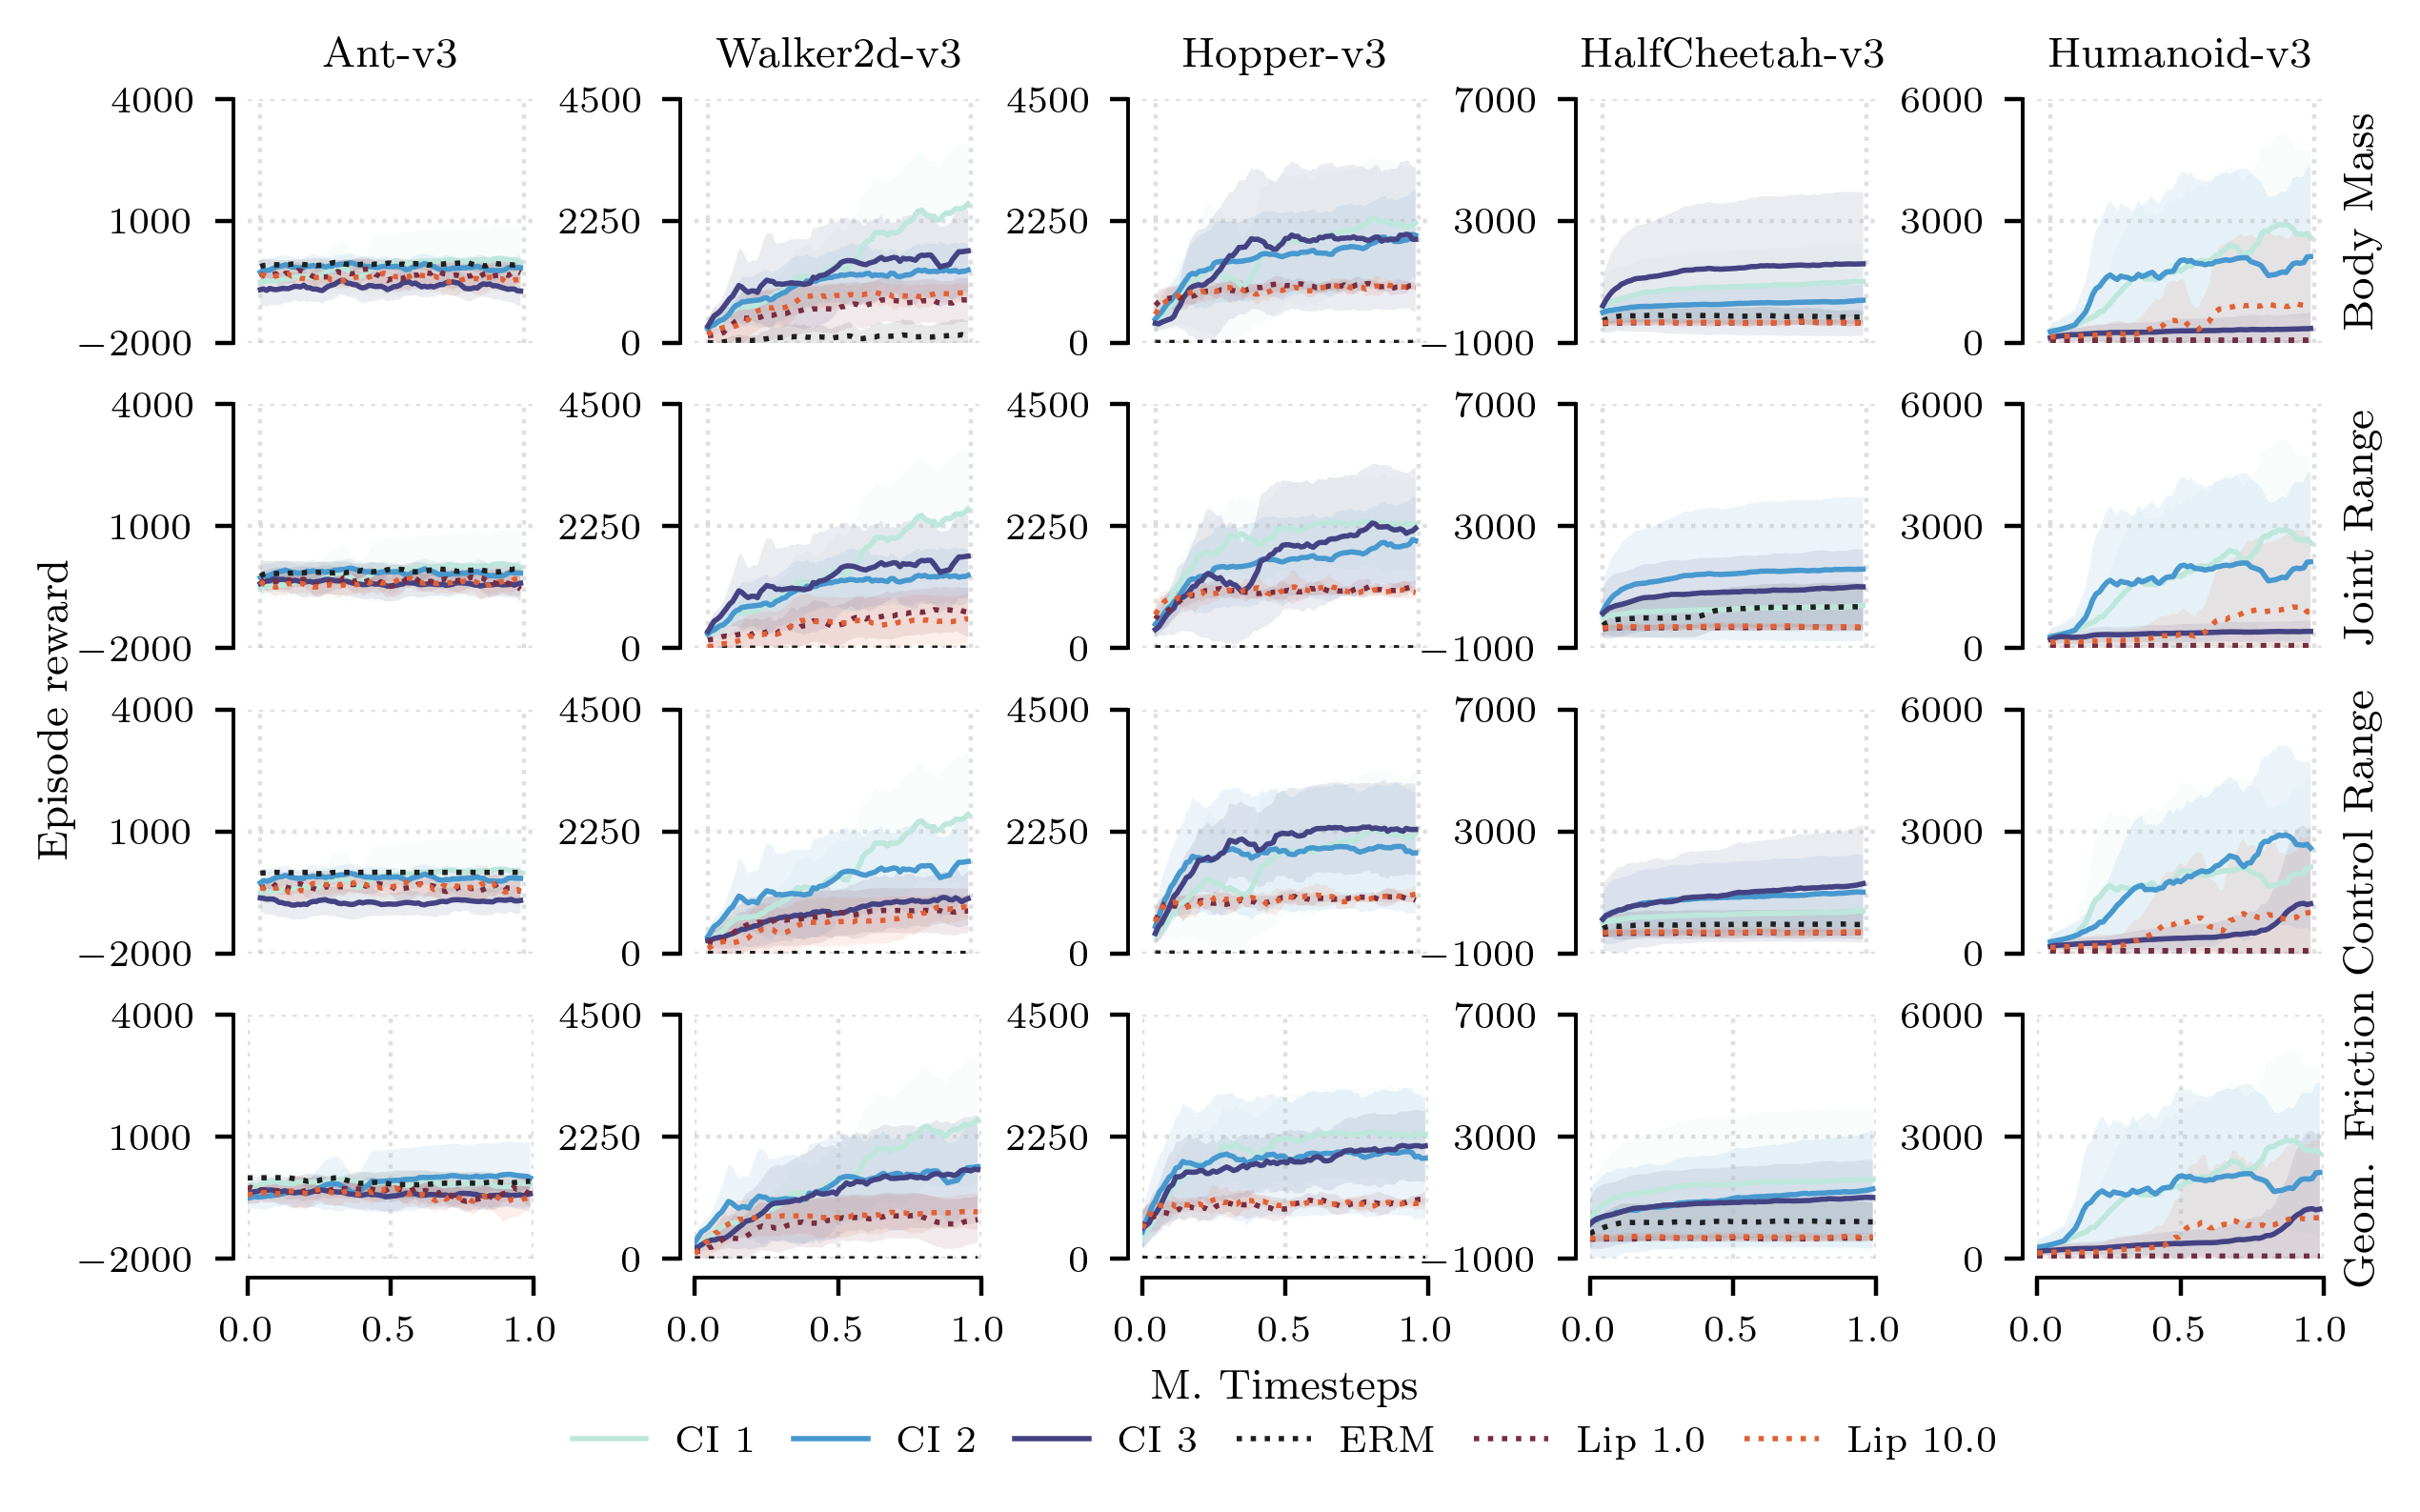

In [177]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

#results_file = results_500k800k
results_files = {'sac_airl201': (results_airl_200k, '200000', '0.1'),
                 'sac_airl202': (results_airl_200k_pert02, '200000', '0.2'), 
                 'sac_gail201': (results_gail_200k, '200000', '0.1'), 
                 'sac_gail503': (results_gail_200k_03, '500000', '0.3'), 
                 'sac_airl801': (results_airl_800k, '800000', '0.1'), 
                 'sac_gail801': (results_gail_800k, '800000', '0.1'), 
                 'sac_meirl801': (results_meirl_800k, '800000', '0.1'),
                 'sac_meirl202': (results_meirl_200k, '200000', '0.2'),
                 'ppo_airl201': (results_ppo_airl_200k, '200000', '0.1')
                }


results_files = {'sac_airl200': (results_sac_airl_200k_nopert, '200000', '0.0'),
                 'sac_gail200': (results_sac_gail_200k_nopert, '200000', '0.0'), 
                 'sac_meirl200': (results_sac_meirl_200k_nopert, '200000', '0.0')
                }

results_files = {'sac_gail503': (results_gail_200k_03, '500000', '0.3')}
results_files = {'td3_airl201': (results_td3_airl_200k, '200000', '0.1')}
results_files = {'sac_airl210': (results_airl_200k_pert10, '200000', '1.0')}
results_files = {'sac_airl205': (results_airl_200k_pert05, '200000', '0.5')}
results_files = {'sac_airl20c': (results_airl_clean, '200000', '0.1')}

results_files = {'sac_airl202': (results_airl_200k_pert02, '200000', '0.2')}
results_files = {'sac_gail201': (results_gail_200k, '200000', '0.1')}
results_files = {'sac_meirl801': (results_meirl_800k, '800000', '0.1')}


d = {}
for env in envs:
    d[env] = {}
    for irm_c in irm_coeffs:
        d[env][irm_c] = {}
        for lip_c in lip_coeffs:
            d[env][irm_c][lip_c] = {}
            for pert in ['bm','jnt','ctrl','geom']:
                d[env][irm_c][lip_c][pert] = {}


d_mu = {}
for env in envs:
    d_mu[env] = {}
    for pert in ['bm','jnt','ctrl','geom']:
        d_mu[env][pert] = []
        
for k,v in results_files.items():
    algo = k[:-3]
    res_file = v[0]
    disc_iter = v[1]
    perturbation_magnitude = v[2]
    #advtra_rew_type = 'rtonlyrew'
    advtra_rew_type = 'runs'

    d_airl_bm, d_airl_bm_mustd = process_results(envs, res_file, advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['body_mass']",disc_iter])
    d_airl_jnt, d_airl_jnt_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['jnt_range']",disc_iter])
    d_airl_ctrl, d_airl_ctrl_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['actuator_ctrlrange']",disc_iter])
    d_airl_friction, d_airl_friction_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['geom_friction']",disc_iter])

    d_mustds = {'bm': d_airl_bm_mustd,
                'jnt': d_airl_jnt_mustd, 
                'ctrl': d_airl_ctrl_mustd,
                'geom': d_airl_friction_mustd}

    ###
    envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
    env_exp = [5150, 4050, 3607, 8900, 6249]

    n_demos = [1,4,10]
    sss = [1]
    subsample_plot = 1
    NUM_COLORS = 6
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)
    #cm2 =sns.color_palette("inferno", as_cmap=True)

    from itertools import cycle

    linestyle_tuple = [
         ('solid', 'solid'), 
         ('dashdot', 'dashdot'),
         ('dotted',                (0, (1, 1))),
         ('densely dotted',        (0, (1, 1))),
         ('densely dashed',        (0, (5, 1))),
         ('dashdotted',            (0, (3, 5, 1, 5))),
         ('densely dashdotted',    (0, (3, 1, 1, 1))),
         ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
         ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

    linecycler = cycle(linestyle_tuple[:NUM_COLORS])

    text_width = 6
    text_height = 9.0
    fig,ax = plt.subplots(len(d_mustds),5, dpi=400, figsize=[text_width, 3.5])
    #fig.tight_layout(w_pad=1, h_pad=1)
    fig.tight_layout(h_pad=-0.5,w_pad=1)

    for i, (k,v) in enumerate(d_mustds.items()):       
        for l, irm_c in enumerate([0.0,0.1, 1.0, 10.0, 100.0]):
            for m, lip_c in enumerate(lip_coeffs):
                for j, env in enumerate(envs):
                    # plot gail
                    mu_ = np.mean(v[env][irm_c][lip_c][0])
                    d[env][irm_c][lip_c][k] = v[env][irm_c][lip_c]
                    if irm_c > 0.0:
                        d_mu[env][k].append([mu_, env, irm_c, lip_c])
                    


#for i, (k,v) in enumerate(d_mustds.items()):       
for i, pert in enumerate(['bm','jnt','ctrl','geom']):
    for j, env in enumerate(envs):

        ax[i,j].set_prop_cycle('color', [cm(1.*r/NUM_COLORS) for r in range(NUM_COLORS)])

        ax[0,j].set_title(env)
        #if j > 0:
            #remove_yticks(ax[i,j])
            #ax[i,j].spines[['left']].set_visible(False)

        #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

        if i < 3:
            ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
            remove_xticks(ax[i,j])

        ax[i,j].spines[['top' , 'right']].set_visible(False)
        ax[i,j].spines['left'].set_position(('axes', -0.05))
        ax[i,j].spines['bottom'].set_position(('axes', -0.08))

        ax[i,j].grid(alpha=0.4, linestyle=':')

        # set env specific limits
        ax[i,0].set_ylim(-2000, 4000)
        ax[i,0].set_yticks([-2000, 1000, 4000])
        ax[i,1].set_ylim(0, 4500)
        ax[i,1].set_yticks([0, 2250, 4500])
        ax[i,2].set_ylim(0, 4500)
        ax[i,2].set_yticks([0, 2250, 4500])            
        ax[i,3].set_ylim(-1000, 7000)
        ax[i,3].set_yticks([-1000, 3000, 7000])                        
        ax[i,4].set_ylim(0, 6000)
        ax[i,4].set_yticks([0, 3000, 6000])                                          
        ax[3,j].set_xlim(0,1.0)
        ax[3,j].set_xticks([0, 0.5, 1.0])


        sorted_d_mu = sorted(d_mu[env][pert], key=lambda x: x[0],reverse=True)
        for l, itm in enumerate(sorted_d_mu):
            if l > 2:
                break
                
            irm_c = itm[2]
            lip_c = itm[3]
            mu,std = d[env][irm_c][lip_c][k]
            mu,std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            
            x = np.arange(len(mu))/len(mu)
            #ax[i,j].plot(x, mu, lw=plot_lw, label=f"$\lambda_I$:{irm_c} $\lambda_L$:{lip_c}")#, linestyle=next(linecycler)[-1])
            ax[i,j].plot(x, mu, lw=plot_lw, label=f"CI {l+1}")#, linestyle=next(linecycler)[-1])

            ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
            
            
        # plot ERM
        for lip_c in [0.0,1.0,10.0]:
            mu,std = d[env][0.0][lip_c][pert]
            mu,std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]

            x = np.arange(len(mu))/len(mu)
            if lip_c == 0.0:
                label = "ERM"
            else:
                label = f"Lip {lip_c}"
            #ax[i,j].plot(x, mu, lw=plot_lw, label=f"$\lambda_I$:{0.0} $\lambda_L$:{lip_c}", linestyle=':')
            ax[i,j].plot(x, mu, lw=plot_lw, label=label, linestyle=':')
            ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)

    
        #ax[i,j].plot(x, mu, lw=plot_lw, label=f"$\lambda_I$:{irm_c} $\lambda_L$:{lip_c}")#, linestyle=next(linecycler)[-1])


    ax[3,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.55), fancybox=False, 
                   shadow=False, frameon=False, ncol=6, columnspacing=1.0, handlelength=2.0)
    ax[3,2].set_xlabel('M. Timesteps')
    ax[1,0].set_ylabel('Episode reward')
    ax[1,0].yaxis.set_label_coords(-0.6,-0.25)

    ax[0,-1].yaxis.set_label_position("right")
    ax[1,-1].yaxis.set_label_position("right")
    ax[2,-1].yaxis.set_label_position("right") 
    ax[3,-1].yaxis.set_label_position("right") 

    ax[0,-1].set_ylabel("Body Mass", rotation=90)
    ax[1,-1].set_ylabel("Joint Range", rotation=90)
    ax[2,-1].set_ylabel("Control Range", rotation=90)
    ax[3,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_{algo}_{disc_iter}_{perturbation_magnitude}.pdf", bbox_inches='tight', pad_inches=0.01, dpi=400)

In [7]:
## Display results of adversarial training

In [3]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3', 'LunarLanderContinuous-v2', 'BipedalWalker-v3']
#envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']#, 'LunarLanderContinuous-v2', 'BipedalWalker-v3']

#results_file = results_500k800k
results_files = {'sac_airl': results_airl_advtra,
                 'sac_gail': results_gail_advtra,
                'sac_meirl': results_meirl_advtra}

d_mustds = {}
for k,v in results_files.items():
    d_, d_mustd = process_results(envs, v, advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name'],
                                            param_filter_value_list=['True',k])

    d_mustds[k] = d_mustd

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("inferno", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
text_width = 6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds), len(envs), dpi=400, figsize=[text_width, 2.5])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5, w_pad=1)


d = {}
for env in envs:
    d[env] = {}
    for irm_c in irm_coeffs:
        d[env][irm_c] = {}
        for lip_c in lip_coeffs:
            d[env][irm_c][lip_c] = {}
            for i, (k,v) in enumerate(d_mustds.items()):       
                d[env][irm_c][lip_c][k] = {}

d_mu = {}
for env in envs:
    d_mu[env] = {}
    for i, (k,v) in enumerate(d_mustds.items()):       
        d_mu[env][k] = []

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate([0.0,0.1, 1.0, 10.0, 100.0]):
        for m, lip_c in enumerate(lip_coeffs):
            for j, env in enumerate(envs):
                # plot gail
                mu_ = np.mean(v[env][irm_c][lip_c][0])
                d[env][irm_c][lip_c][k] = v[env][irm_c][lip_c]
                if irm_c > 0.0:
                    d_mu[env][k].append([mu_, env, irm_c, lip_c])


for i, (k,v) in enumerate(d_mustds.items()):       
    for j, env in enumerate(envs):
        # plot gail
        ax[i,j].set_prop_cycle('color', [cm(1.*r/NUM_COLORS) for r in range(NUM_COLORS)])

        ax[0,j].set_title(env)
        #if j > 0:
            #remove_yticks(ax[i,j])
            #ax[i,j].spines[['left']].set_visible(False)

        #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

        if i < 2:
            ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
            remove_xticks(ax[i,j])
            ax[i,j].axvline(0.5, ymin=0, ymax=1, c='gray', lw=.8, linestyle='dotted', alpha=0.4)
            

        ax[i,j].spines[['top' , 'right']].set_visible(False)
        ax[i,j].spines['left'].set_position(('axes', -0.05))
        ax[i,j].spines['bottom'].set_position(('axes', -0.08))

        ax[i,j].grid(alpha=0.4, linestyle=':')

        # set env specific limits
        ax[i,0].set_ylim(-2000, 5200)
        ax[i,0].set_yticks([-2000, 1600, 5200])
        ax[i,1].set_ylim(0, 4500)
        ax[i,1].set_yticks([0, 2250, 4500])
        ax[i,2].set_ylim(0, 4500)
        ax[i,2].set_yticks([0, 2250, 4500])            
        ax[i,3].set_ylim(-1000, 9000)
        ax[i,3].set_yticks([-1000, 4000, 9000])                        
        ax[i,4].set_ylim(0, 7000)
        ax[i,4].set_yticks([0, 3500, 7000])                                          
        ax[2,j].set_xlim(0,1.0)
        ax[2,j].set_xticks([0, 0.5, 1.0])

                
        sorted_d_mu = sorted(d_mu[env][k], key=lambda x: x[0],reverse=True)
        for l, itm in enumerate(sorted_d_mu):
            if l > 2:
                break

            irm_c = itm[2]
            lip_c = itm[3]
            mu,std = d[env][irm_c][lip_c][k]
            mu,std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]

            x = np.arange(len(mu))/len(mu)
            #ax[i,j].plot(x, mu, lw=plot_lw, label=f"$\lambda_I$:{irm_c} $\lambda_L$:{lip_c}")#, linestyle=next(linecycler)[-1])
            ax[i,j].plot(x, mu, lw=plot_lw, label=f"CI {l+1}")#, linestyle=next(linecycler)[-1])

            ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)


        # plot ERM
        for lip_c in [0.0,1.0,10.0]:
            mu,std = d[env][0.0][lip_c][k]
            mu,std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]

            x = np.arange(len(mu))/len(mu)
            if lip_c == 0.0:
                label = "ERM"
            else:
                label = f"Lip {lip_c}"
            #ax[i,j].plot(x, mu, lw=plot_lw, label=f"$\lambda_I$:{0.0} $\lambda_L$:{lip_c}", linestyle=':')
            ax[i,j].plot(x, mu, lw=plot_lw, label=label, linestyle=':')
            ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)


            ax[2,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.6), fancybox=False, shadow=False, frameon=False, ncol=6)
            ax[2,2].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            #ax[3,-1].yaxis.set_label_position("right") 

            ax[0,-1].set_ylabel("AIRL", rotation=90)
            ax[1,-1].set_ylabel("GAIL", rotation=90)
            ax[2,-1].set_ylabel("MEIRL", rotation=90)
            #ax[3,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig("fig_advtra.pdf", bbox_inches='tight', pad_inches=0.01, dpi=400)

NameError: name 'process_results' is not defined

### Generate tables

In [29]:
from texttable import Texttable
import latextable

#### Adv. tra. results

In [81]:
####### create table with results
table_rows = [["Model", "Ant-v3", "Walker2d-v3", "Hopper-v3", "HalfCheetah-v3", "Humanoid-v3"]]

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]
results_files = {'sac_airl': results_airl_advtra,
                 'sac_gail': results_gail_advtra,
                'sac_meirl': results_meirl_advtra}

envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3', 'LunarLanderContinuous-v2', 'BipedalWalker-v3']

for k,v in results_files.items():
            
    d_, d_mustd = process_results(envs, v, advtra_rew_type=advtra_rew_type,
                                param_filter_key_list=['use_actions','exp_name'],
                                param_filter_value_list=['True',k])
    
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):        

            for idx in [20, 50, -1]:          
                table_row = [f"{k}_{irm_c}_{lip_c}_{idx}"]
                for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:    
                    mu,std = d_mustd[env][irm_c][lip_c]
                    table_row.append(f"{mu[idx]:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std[idx]:.2f}" + "}$")

                table_rows.append(table_row)
            
table_1 = Texttable()

table_1.set_cols_align(["c" for i in range(len(table_rows[0]))])
table_1.set_cols_valign(["c" for i in range(len(table_rows[0]))])
table_1.add_rows(table_rows)
print('Texttable Output:')
print(table_1.draw())
print('\nLatextable Output:')
print(latextable.draw_latex(table_1, caption="An example table.", label="table:example_table"))

Computing mu/std
Incomplete length: sac_airl Ant-v3 234 0.0 0.0 58
Incomplete length: sac_airl Ant-v3 894 0.0 0.0 87
Incomplete length: sac_airl Ant-v3 72 0.0 0.0 81
Incomplete length: sac_airl Ant-v3 234 0.1 0.0 58
Incomplete length: sac_airl Ant-v3 894 0.1 0.0 86
Incomplete length: sac_airl Ant-v3 322 0.1 0.0 72
Incomplete length: sac_airl Ant-v3 72 0.1 0.0 71
Incomplete length: sac_airl Ant-v3 234 1.0 0.0 74
Incomplete length: sac_airl Ant-v3 322 1.0 0.0 49
Incomplete length: sac_airl Ant-v3 72 1.0 0.0 75
Incomplete length: sac_airl Walker2d-v3 515 0.0 0.0 73
Incomplete length: sac_airl Walker2d-v3 234 0.0 0.0 45
Incomplete length: sac_airl Walker2d-v3 894 0.0 0.0 38
Incomplete length: sac_airl Walker2d-v3 322 0.0 0.0 78
Incomplete length: sac_airl Walker2d-v3 72 0.0 0.0 52
Incomplete length: sac_airl Walker2d-v3 515 0.1 0.0 73
Incomplete length: sac_airl Walker2d-v3 234 0.1 0.0 45
Incomplete length: sac_airl Walker2d-v3 894 0.1 0.0 41
Incomplete length: sac_airl Walker2d-v3 322 0.1

#### Load on perturbed dynamics results

In [174]:
####### create table with results
table_rows = [["Model", "Ant-v3", "Walker2d-v3", "Hopper-v3", "HalfCheetah-v3", "Humanoid-v3"]]
best_table_rows = [["Model", "Ant-v3", "Walker2d-v3", "Hopper-v3", "HalfCheetah-v3", "Humanoid-v3"]]

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]
results_files = {'sac_airl200': (results_airl_200k, '200000', '0.1'),
                 'sac_airl202': (results_airl_200k_pert02, '200000', '0.2'), 
                 'sac_gail200': (results_gail_200k, '200000', '0.1'), 
                 'sac_airl800': (results_airl_800k, '800000', '0.1'), 
                 'sac_gail800': (results_gail_800k, '800000', '0.1'), 
                 'sac_meirl800': (results_meirl_800k, '800000', '0.1'),
                 'sac_meirl200': (results_meirl_200k, '200000', '0.2'),
                 'ppo_airl200': (results_ppo_airl_200k, '200000', '0.1')
                }
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3', 'LunarLanderContinuous-v2', 'BipedalWalker-v3']

for k,v in results_files.items():
    algo = k[:-3]
    res_file = v[0]
    disc_iter = v[1]
    perturbation_magnitude = v[2]

    
    d_airl_bm, d_airl_bm_mustd = process_results(envs, res_file, advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['body_mass']",disc_iter])
    d_airl_jnt, d_airl_jnt_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['jnt_range']",disc_iter])
    d_airl_ctrl, d_airl_ctrl_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['actuator_ctrlrange']",disc_iter])
    d_airl_friction, d_airl_friction_mustd = process_results(envs, res_file,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['geom_friction']",disc_iter])
        

    d_mustds = {'Body Mass': d_airl_bm_mustd,
               'Joint Range': d_airl_jnt_mustd,
               'Ctrl. Range': d_airl_ctrl_mustd,
               'Geom. Friction': d_airl_friction_mustd}
        
    for pert_name, d_mustd_ in d_mustds.items():
        table_rows.append([pert_name + f" ({k})", "----", "----","----", "----", "----"])
        best_table_rows.append([pert_name + f" ({k})", "----", "----","----", "----", "----"])
        
        best_erm = {'Ant-v3': (-5000.0, 0.0), 
                    'Walker2d-v3': (-5000.0, 0.0), 
                    'Hopper-v3': (-5000.0, 0.0), 
                    'HalfCheetah-v3': (-5000.0, 0.0), 
                    'Humanoid-v3': (-5000.0, 0.0)}
        best_lip = {'Ant-v3': ((-5000.0, 0.0),0.0),
                    'Walker2d-v3': ((-5000.0, 0.0),0.0),
                    'Hopper-v3': ((-5000.0, 0.0),0.0), 
                    'HalfCheetah-v3': ((-5000.0, 0.0),0.0),
                    'Humanoid-v3': ((-5000.0, 0.0),0.0)}
        best_ci = {'Ant-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Walker2d-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Hopper-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'HalfCheetah-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Humanoid-v3': ((-5000.0, 0.0),(0.0,0.0))}

        
        ## add all results and keep track of best ones
        for l, irm_c in enumerate(irm_coeffs):
            for m, lip_c in enumerate(lip_coeffs):        

                if irm_c == 0.0:
                    table_row = [f">> {k}_{irm_c}_{lip_c}"]
                else:
                    table_row = [f"{k}_{irm_c}_{lip_c}"]


                for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:    
                    mu,std = d_mustd_[env][irm_c][lip_c]
                    table_row.append(f"{mu[-1]:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std[-1]:.2f}" + "}$")
                                     
                    if irm_c == 0.0 and lip_c > 0.0:
                        if mu[-1] > best_lip[env][0][0]:
                            best_lip[env] = ((mu[-1], std[-1]), lip_c)
                    elif irm_c > 0.0:
                        if mu[-1] > best_ci[env][0][0]:
                            best_ci[env] = ((mu[-1], std[-1]), (irm_c, lip_c))
                    else:
                        best_erm[env] = (mu[-1], std[-1])

                    
                table_rows.append(table_row)

        ## add best results per perturbation
        for i, best_ in enumerate([best_erm, best_lip, best_ci]):
            
            # compose label: 
            if 'airl' in k:
                row_name = "AIRL"
            elif 'gail' in k:
                row_name = "GAIL"
            elif 'meirl' in k:
                row_name = "MEIRL"
                
            regs = ["ERM", "Lip", "CI"]
            
            table_row = [f"{row_name} ({regs[i]})"]

            for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:    
                if i == 0:
                    mu_ = best_[env][0]
                    std_ = best_[env][1]
                    table_row.append(f"{mu_:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std_:.2f}" + "}$")
                elif i == 1:
                    mu_ = best_[env][0][0]
                    std_ = best_[env][0][1]
                    best_lip_c = best_[env][1]
                    table_row.append(f"{mu_:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std_:.2f}" + "}$")# + f" ({best_lip_c})")                
                else:
                    mu_ = best_[env][0][0]
                    std_ = best_[env][0][1]
                    best_irm_c = best_[env][1][0]
                    best_lip_c = best_[env][1][1]
                    table_row.append(f"{mu_:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std_:.2f}" + "}$")# + f" ({best_lip_c}, {best_irm_c})")                      

            table_rows.append(table_row)
            best_table_rows.append(table_row)

                
table_1 = Texttable()

table_1.set_cols_align(["c" for i in range(len(table_rows[0]))])
table_1.set_cols_valign(["c" for i in range(len(table_rows[0]))])
#table_1.add_rows(table_rows)
table_1.add_rows(best_table_rows)

#print('Texttable Output:')
#print(table_1.draw())
print('\nLatextable Output:')
print(latextable.draw_latex(table_1, caption="An example table.", label="table:example_table"))


Computing mu/std
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Incomplete length: sac_airl Walker2d-v3 72 0.0 0.0 71
Incomplete length: sac_airl Walker2d-v3 72 0.1 0.0 61
Incomplete length: sac_airl Walker2d-v3 72 1.0 0.0 84
Incomplete length: sac_airl Walker2d-v3 72 10.0 0.0 50
Incomplete length: sac_airl Hopper-v3 234 1.0 1.0 74
Missing tuple for ('HalfCheetah-v3', 894, 0.0, 1.0)
Missing tuple for ('HalfCheetah-v3', 894, 0.0, 10.0)
Missing tuple for ('HalfCheetah-v3', 322, 0.1, 10.0)
Missing tuple for ('HalfCheetah-v3', 322, 1.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 322, 1.0, 1.0)
Missing tuple for ('HalfCheetah-v3', 322, 1.0, 10.0)
Missing tuple for ('HalfCheetah-v3', 322, 10.0, 1.0)
Missing tuple for ('Humanoid-v3', 234, 0.0, 0.0)
Missing tuple for ('Humanoid-v3', 894, 0.0, 0.0)
Missing tuple for ('Humanoid-v3', 72, 0.0, 0.0)
Missing tuple for ('Humanoid-v3', 234, 0.1, 0.0)
Missing tuple for ('Humanoid-v3', 322, 0.1, 0.0)
Missing tuple for ('Humanoid-v3', 72, 0.1, 0.0)
Missing t

### Compose plots of performance vs perturbation strength

Computing mu/std
Incomplete length: sac_airl Humanoid-v3 894 0.0 0.0 79
Incomplete length: sac_airl Humanoid-v3 322 0.0 1.0 79
Incomplete length: sac_airl Humanoid-v3 894 0.0 10.0 79
Incomplete length: sac_airl Humanoid-v3 234 0.1 0.0 79
Incomplete length: sac_airl Humanoid-v3 894 0.1 10.0 79
Incomplete length: sac_airl Humanoid-v3 72 1.0 0.0 79
Incomplete length: sac_airl Humanoid-v3 72 1.0 10.0 79
Incomplete length: sac_airl Humanoid-v3 894 10.0 0.0 79
Incomplete length: sac_airl Humanoid-v3 234 10.0 1.0 79
Incomplete length: sac_airl Humanoid-v3 234 100.0 0.0 79
Incomplete length: sac_airl Humanoid-v3 894 100.0 0.0 79
Incomplete length: sac_airl Humanoid-v3 322 100.0 1.0 79
Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Missing tuple for ('Ant-v3', 515, 0.0, 1.0)
Missing tuple for ('Ant-v3', 234, 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


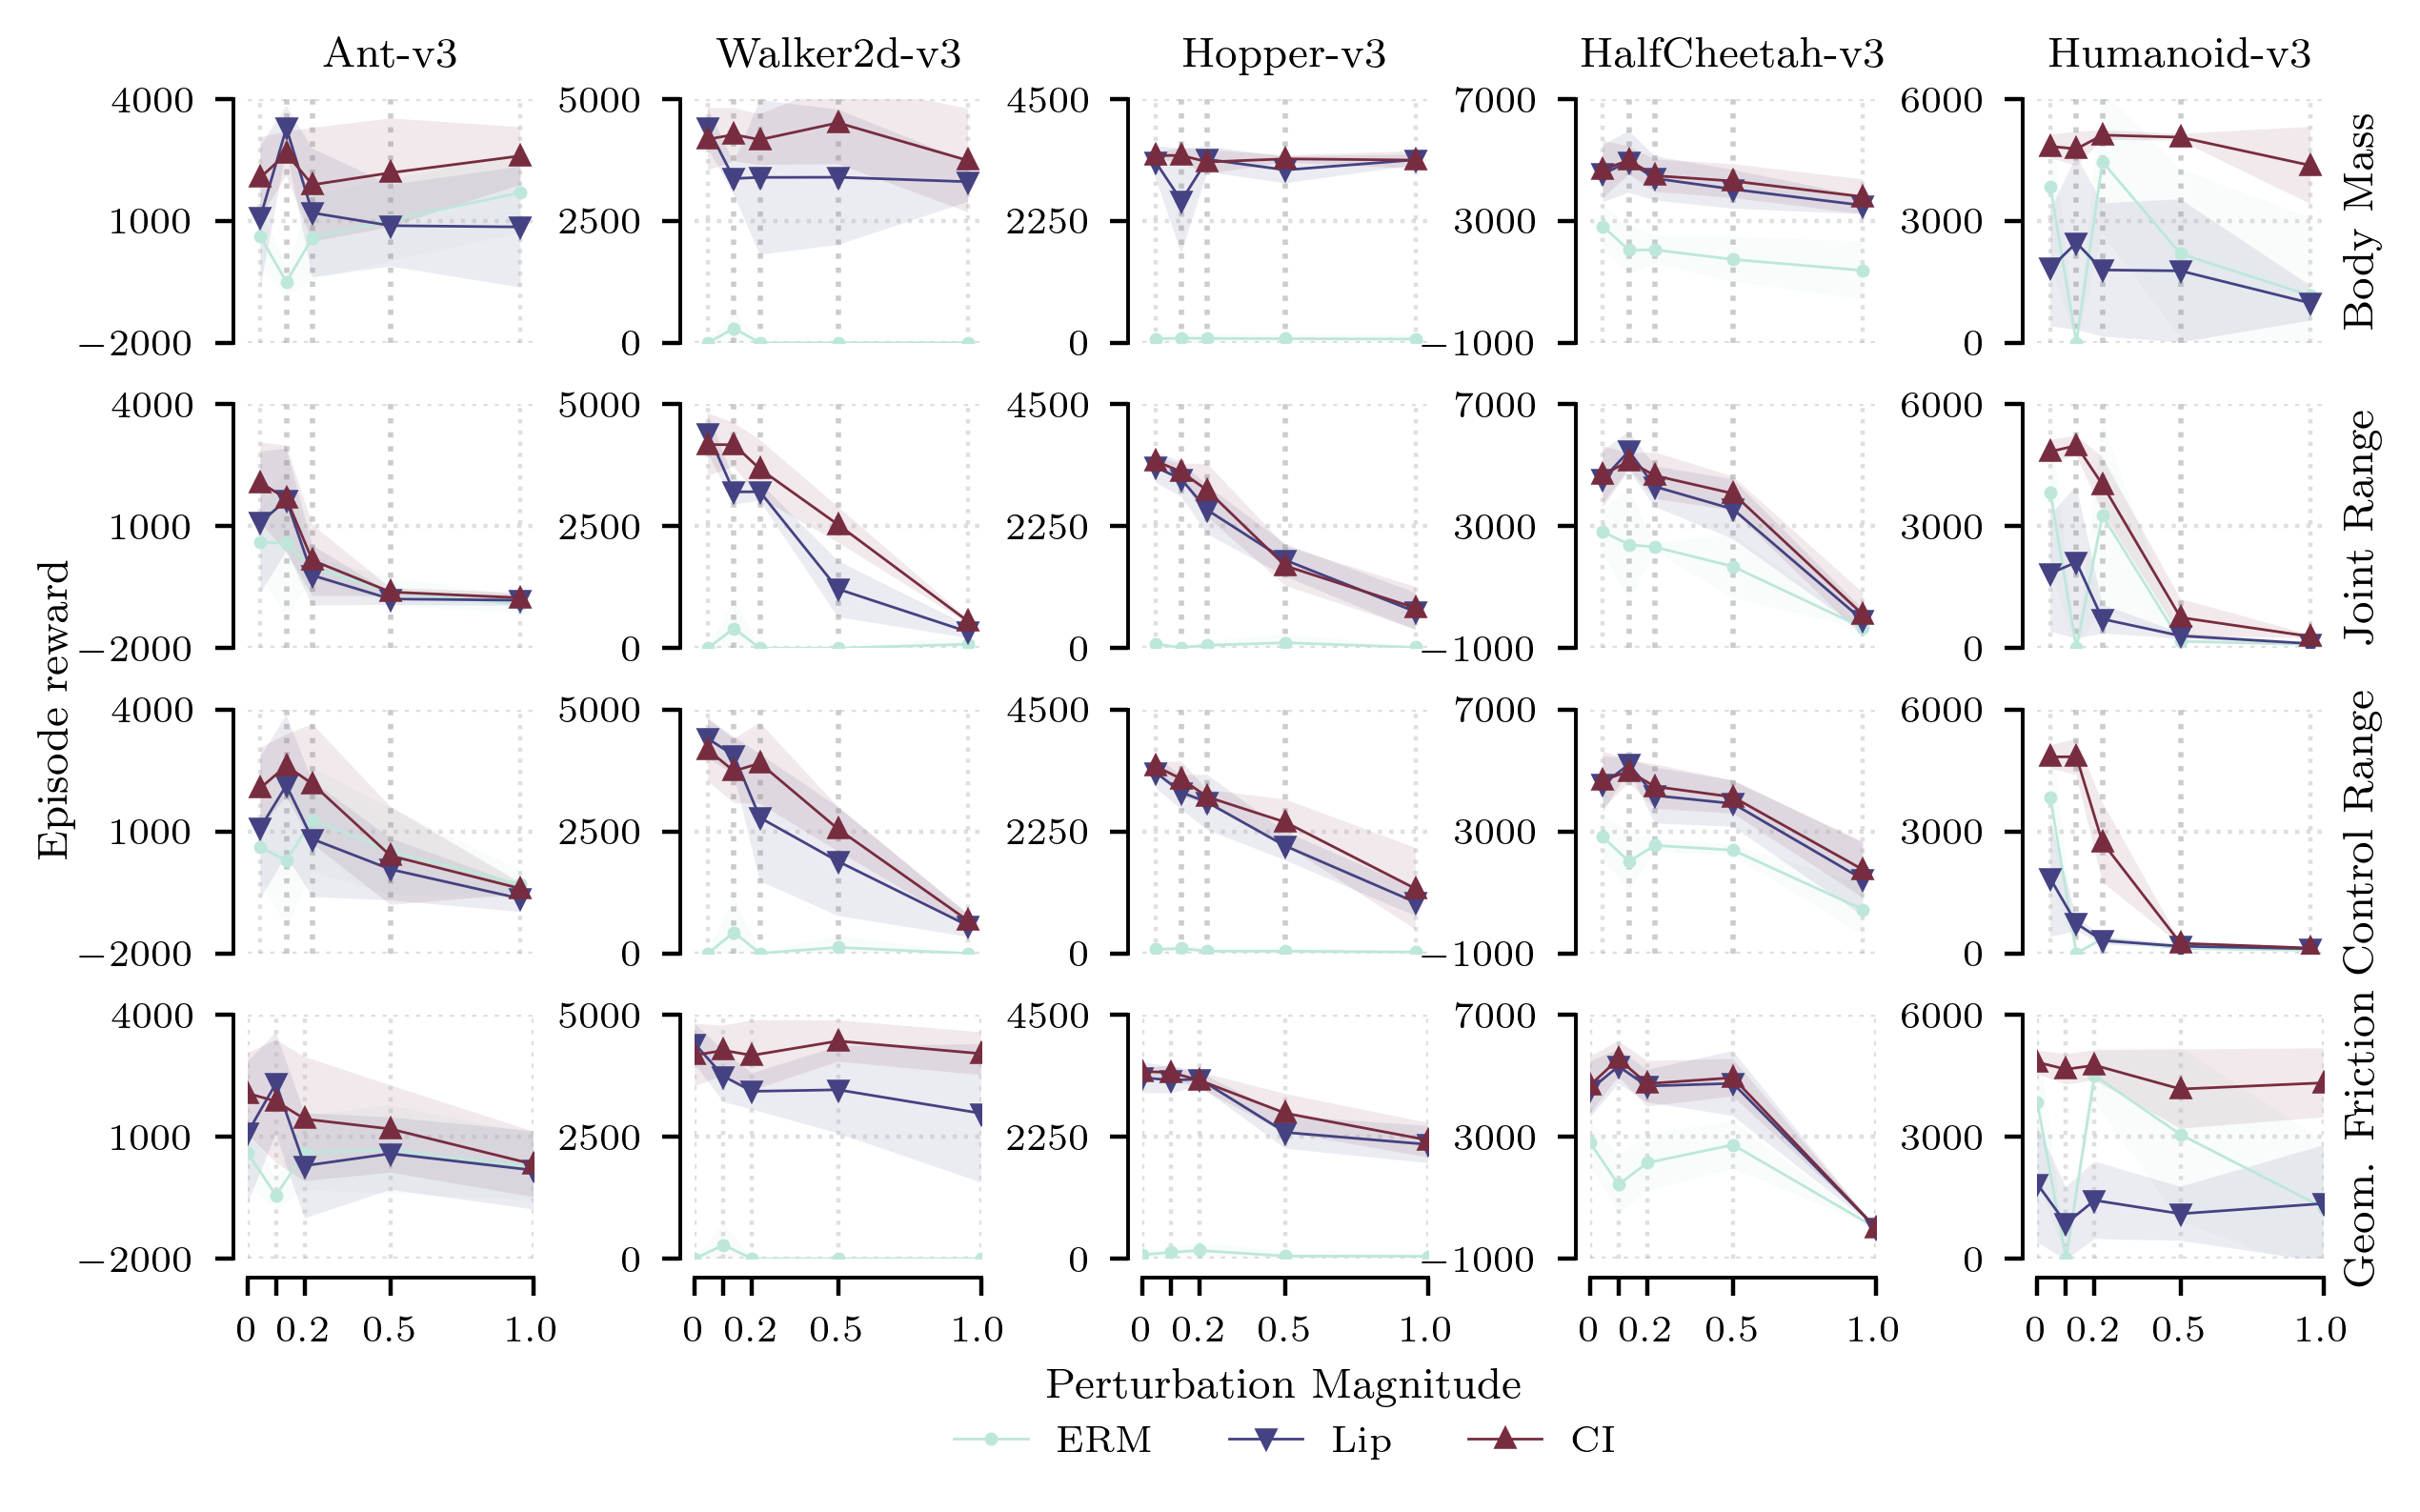

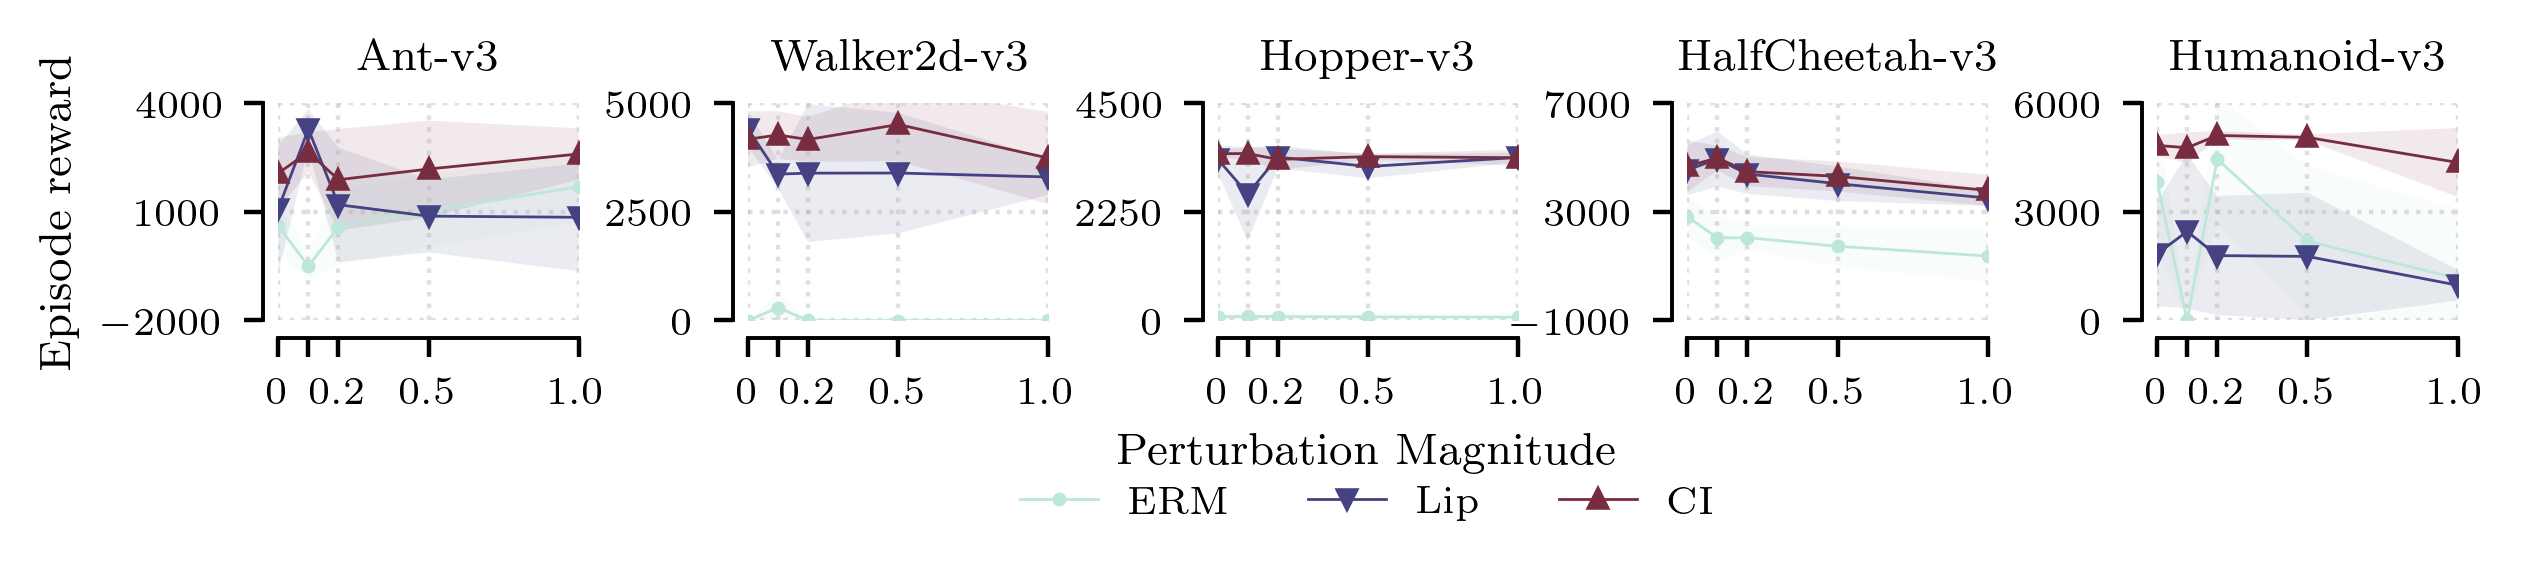

In [152]:
d_perf_pert = {0.0: results_sac_airl_200k_nopert, 
               0.1: results_airl_200k, 
               0.2: results_airl_200k_pert02,
               0.5: results_airl_200k_pert05,
               1.0: results_airl_200k_pert10}

d_pert_pert_anthum = {0.5: results_airl_anthum_200k_pert05,
                      1.0: results_airl_anthum_200k_pert10}

d_perf_pert_val = {0.0: {'Body Mass': [], 'Joint Range': [], 'Ctrl. Range': [], 'Geom. Friction': []},
                   0.1: {'Body Mass': [], 'Joint Range': [], 'Ctrl. Range': [], 'Geom. Friction': []},
                   0.2: {'Body Mass': [], 'Joint Range': [], 'Ctrl. Range': [], 'Geom. Friction': []},
                   0.5: {'Body Mass': [], 'Joint Range': [], 'Ctrl. Range': [], 'Geom. Friction': []},
                   1.0: {'Body Mass': [], 'Joint Range': [], 'Ctrl. Range': [], 'Geom. Friction': []}}

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

advtra_rew_type = 'rtonlyrew'
idx = -1
for k,v in d_perf_pert.items():

    algo = 'sac_airl'
    perturbation_magnitude = str(k)
    disc_iter = '200000'
    
    
    d_airl_bm, d_airl_bm_mustd = process_results(envs, v, advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['body_mass']",disc_iter])
    d_airl_jnt, d_airl_jnt_mustd = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['jnt_range']",disc_iter])
    d_airl_ctrl, d_airl_ctrl_mustd = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['actuator_ctrlrange']",disc_iter])
    d_airl_friction, d_airl_friction_mustd = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['geom_friction']",disc_iter])

    if k > 0.4:
        v = d_pert_pert_anthum[k]
        d_airl_bm, d_airl_bm_mustd_ = process_results(envs, v, advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['body_mass']",disc_iter])
        d_airl_jnt, d_airl_jnt_mustd_ = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['jnt_range']",disc_iter])
        d_airl_ctrl, d_airl_ctrl_mustd_ = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['actuator_ctrlrange']",disc_iter])
        d_airl_friction, d_airl_friction_mustd_ = process_results(envs, v,  advtra_rew_type=advtra_rew_type,
                                            param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters','load_disc_timestep'],
                                            param_filter_value_list=['True',algo,perturbation_magnitude,"['geom_friction']",disc_iter])
    
        d_mustds_add = {'Body Mass': d_airl_bm_mustd_,
               'Joint Range': d_airl_jnt_mustd_,
               'Ctrl. Range': d_airl_ctrl_mustd_,
               'Geom. Friction': d_airl_friction_mustd_}
    
    if k == 0.0:
        d_mustds = {'Body Mass': d_airl_bm_mustd,
               'Joint Range': d_airl_bm_mustd,
               'Ctrl. Range': d_airl_bm_mustd,
               'Geom. Friction': d_airl_bm_mustd}
    else:
        d_mustds = {'Body Mass': d_airl_bm_mustd,
               'Joint Range': d_airl_jnt_mustd,
               'Ctrl. Range': d_airl_ctrl_mustd,
               'Geom. Friction': d_airl_friction_mustd}
        
    for pert_name, d_mustd_ in d_mustds.items():
        
        best_erm = {'Ant-v3': (-5000.0, 0.0), 
                    'Walker2d-v3': (-5000.0, 0.0), 
                    'Hopper-v3': (-5000.0, 0.0), 
                    'HalfCheetah-v3': (-5000.0, 0.0), 
                    'Humanoid-v3': (-5000.0, 0.0)}
        best_lip = {'Ant-v3': ((-5000.0, 0.0),0.0),
                    'Walker2d-v3': ((-5000.0, 0.0),0.0),
                    'Hopper-v3': ((-5000.0, 0.0),0.0), 
                    'HalfCheetah-v3': ((-5000.0, 0.0),0.0),
                    'Humanoid-v3': ((-5000.0, 0.0),0.0)}
        best_ci = {'Ant-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Walker2d-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Hopper-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'HalfCheetah-v3': ((-5000.0, 0.0),(0.0,0.0)),
                    'Humanoid-v3': ((-5000.0, 0.0),(0.0,0.0))}

        
        ## add all results and keep track of best ones
        for l, irm_c in enumerate(irm_coeffs):
            for m, lip_c in enumerate(lip_coeffs):        
                for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:
                    if k > 0.4 and env in ['Ant-v3','Humanoid-v3']:
                        mu,std = d_mustds_add[pert_name][env][irm_c][lip_c]
                    else:
                        mu,std = d_mustd_[env][irm_c][lip_c]
                    #table_row.append(f"{mu[-1]:.2f}$\pm_".replace('\pm_','_{\pm') + f"{std[-1]:.2f}" + "}$")
                                     
                    if irm_c == 0.0 and lip_c > 0.0:
                        if mu[idx] > best_lip[env][0][0]:
                            best_lip[env] = ((mu[idx], std[idx]), lip_c)
                    elif irm_c > 0.0:
                        if mu[idx] > best_ci[env][0][0]:
                            best_ci[env] = ((mu[idx], std[idx]), (irm_c, lip_c))
                    else:
                        best_erm[env] = (mu[idx], std[idx])

        d_perf_pert_val[k][pert_name] = (best_erm, best_lip, best_ci)


###
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
env_exp = [5150, 4050, 3607, 8900, 6249]

subsample_plot = 1
NUM_COLORS = 3
cm =sns.color_palette("icefire", as_cmap=True)
#cm2 =sns.color_palette("inferno", as_cmap=True)

text_width = 6
fig,ax = plt.subplots(len(d_perf_pert_val[0].keys()),len(envs), dpi=400, figsize=[text_width, 3.5])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5, w_pad=1)

plot_perts = ['Body Mass', 'Joint Range', 'Ctrl. Range', 'Geom. Friction'],

for i, pert_name in enumerate(d_mustds.keys()):
    color_cnt = 0
    for j, env_name in enumerate(envs):       

        ax[i,j].set_prop_cycle('color', [cm(1.*l/NUM_COLORS) for l in range(NUM_COLORS)])

        ax[0,j].set_title(env_name)
        #if j > 0:
            #remove_yticks(ax[i,j])
            #ax[i,j].spines[['left']].set_visible(False)

        #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

        if i < 3:
            ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
            for x_t in [0.1, 0.2, 0.5]: 
                ax[i,j].axvline(x_t, ymin=0, ymax=1, c='gray', lw=1, linestyle='dotted', alpha=0.4)
            remove_xticks(ax[i,j])

        ax[i,j].spines[['top' , 'right']].set_visible(False)
        ax[i,j].spines['left'].set_position(('axes', -0.05))
        ax[i,j].spines['bottom'].set_position(('axes', -0.08))

        ax[i,j].grid(alpha=0.4, linestyle=':')

        # set env specific limits
        ax[i,0].set_ylim(-2000, 4000)
        ax[i,0].set_yticks([-2000, 1000, 4000])
        ax[i,1].set_ylim(0, 5000)
        ax[i,1].set_yticks([0, 2500, 5000])
        ax[i,2].set_ylim(0, 4500)
        ax[i,2].set_yticks([0, 2250, 4500])            
        ax[i,3].set_ylim(-1000, 7000)
        ax[i,3].set_yticks([-1000, 3000, 7000])                        
        ax[i,4].set_ylim(0, 6000)
        ax[i,4].set_yticks([0, 3000, 6000])                                          
        ax[3,j].set_xlim(0,1.0)
        ax[3,j].set_xticks([0, 0.1, 0.2, 0.5, 1.0], ['0','','0.2','0.5','1.0'])

        #mu,std = v[env][irm_c][lip_c]
        #mu,std = smooth_mu_std(mu,std)
        #mu = mu[::subsample_plot]
        #std = std[::subsample_plot]

        x = d_perf_pert_val.keys()
        # get x, y pair from dict 
        mu_erm, std_erm = [], []
        mu_lip, std_lip = [], []
        mu_ci, std_ci = [], []

        for k,v in d_perf_pert_val.items():
            mu_erm.append(v[pert_name][0][env_name][0])
            std_erm.append(v[pert_name][0][env_name][1])
            mu_lip.append(v[pert_name][1][env_name][0][0])
            std_lip.append(v[pert_name][1][env_name][0][1])                
            mu_ci.append(v[pert_name][2][env_name][0][0])
            std_ci.append(v[pert_name][2][env_name][0][1])

            
        mu_erm = np.array(mu_erm)
        std_erm = np.array(std_erm)
        mu_lip = np.array(mu_lip)
        std_lip = np.array(std_lip)       
        mu_ci = np.array(mu_ci)
        std_ci = np.array(std_ci)
        
        ms = 3
        ax[i,j].plot(x, mu_erm,lw=plot_lw, label=f"ERM", marker='.', markersize=ms)#, linestyle=next(linecycler)[-1])
        ax[i,j].fill_between(x,mu_erm+std_erm, mu_erm-std_erm, alpha=0.1)

        ax[i,j].plot(x, mu_lip,lw=plot_lw, label=f"Lip", marker='v', markersize=ms)#, linestyle=next(linecycler)[-1])
        ax[i,j].fill_between(x,mu_lip+std_lip, mu_lip-std_lip, alpha=0.1)

        ax[i,j].plot(x, mu_ci,lw=plot_lw, label=f"CI", marker='^', markersize=ms)#, linestyle=next(linecycler)[-1])
        ax[i,j].fill_between(x,mu_ci+std_ci, mu_ci-std_ci, alpha=0.1)


    ax[3,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.55), fancybox=False, shadow=False, frameon=False, ncol=5)
    ax[3,2].set_xlabel('Perturbation Magnitude')
    ax[1,0].set_ylabel('Episode reward')
    ax[1,0].yaxis.set_label_coords(-0.6,-0.25)
    ax[0,-1].yaxis.set_label_position("right")
    ax[1,-1].yaxis.set_label_position("right")
    ax[2,-1].yaxis.set_label_position("right") 
    ax[3,-1].yaxis.set_label_position("right") 

    ax[0,-1].set_ylabel("Body Mass", rotation=90)
    ax[1,-1].set_ylabel("Joint Range", rotation=90)
    ax[2,-1].set_ylabel("Control Range", rotation=90)
    ax[3,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
    #plt.tight_layout()
fig.savefig(f"fig_pertcomp_{algo}_{disc_iter}_{perturbation_magnitude}.pdf", bbox_inches='tight', pad_inches=0.01)


pert_name = "Body Mass"
fig,ax = plt.subplots(1,len(envs), dpi=400, figsize=[text_width, 1.0])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5, w_pad=1)
color_cnt = 0
for j, env_name in enumerate(envs):       

    ax[j].set_prop_cycle('color', [cm(1.*l/NUM_COLORS) for l in range(NUM_COLORS)])

    ax[j].set_title(env_name)

    ax[j].spines[['top' , 'right']].set_visible(False)
    ax[j].spines['left'].set_position(('axes', -0.05))
    ax[j].spines['bottom'].set_position(('axes', -0.08))

    ax[j].grid(alpha=0.4, linestyle=':')

    # set env specific limits
    ax[0].set_ylim(-2000, 4000)
    ax[0].set_yticks([-2000, 1000, 4000])
    ax[1].set_ylim(0, 5000)
    ax[1].set_yticks([0, 2500, 5000])
    ax[2].set_ylim(0, 4500)
    ax[2].set_yticks([0, 2250, 4500])            
    ax[3].set_ylim(-1000, 7000)
    ax[3].set_yticks([-1000, 3000, 7000])                        
    ax[4].set_ylim(0, 6000)
    ax[4].set_yticks([0, 3000, 6000])                                          
    ax[j].set_xlim(0,1.0)
    ax[j].set_xticks([0, 0.1, 0.2, 0.5, 1.0], ['0','','0.2','0.5','1.0'])

    #mu,std = v[env][irm_c][lip_c]
    #mu,std = smooth_mu_std(mu,std)
    #mu = mu[::subsample_plot]
    #std = std[::subsample_plot]

    x = d_perf_pert_val.keys()
    # get x, y pair from dict 
    mu_erm, std_erm = [], []
    mu_lip, std_lip = [], []
    mu_ci, std_ci = [], []

    for k,v in d_perf_pert_val.items():
        mu_erm.append(v[pert_name][0][env_name][0])
        std_erm.append(v[pert_name][0][env_name][1])
        mu_lip.append(v[pert_name][1][env_name][0][0])
        std_lip.append(v[pert_name][1][env_name][0][1])                
        mu_ci.append(v[pert_name][2][env_name][0][0])
        std_ci.append(v[pert_name][2][env_name][0][1])

    mu_erm = np.array(mu_erm)
    std_erm = np.array(std_erm)
    mu_lip = np.array(mu_lip)
    std_lip = np.array(std_lip)       
    mu_ci = np.array(mu_ci)
    std_ci = np.array(std_ci)

    ms = 3
    ax[j].plot(x, mu_erm,lw=plot_lw, label=f"ERM", marker='.', markersize=ms)#, linestyle=next(linecycler)[-1])
    ax[j].fill_between(x,mu_erm+std_erm, mu_erm-std_erm, alpha=0.1)

    ax[j].plot(x, mu_lip,lw=plot_lw, label=f"Lip", marker='v', markersize=ms)#, linestyle=next(linecycler)[-1])
    ax[j].fill_between(x,mu_lip+std_lip, mu_lip-std_lip, alpha=0.1)

    ax[j].plot(x, mu_ci,lw=plot_lw, label=f"CI", marker='^', markersize=ms)#, linestyle=next(linecycler)[-1])
    ax[j].fill_between(x,mu_ci+std_ci, mu_ci-std_ci, alpha=0.1)


ax[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.6), fancybox=False, shadow=False, frameon=False, ncol=5)
ax[2].set_xlabel('Perturbation Magnitude')
ax[0].set_ylabel('Episode reward')

fig.savefig(f"fig_pertcomp_{algo}_{disc_iter}_{perturbation_magnitude}_bodymass.pdf", bbox_inches='tight', pad_inches=0.01)



In [ ]:
### load clean results